In [17]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from scipy.stats import (
    skew,
    kurtosis,
    jarque_bera,
    probplot
)

from statsmodels.tsa.stattools import adfuller

In [18]:
df = pd.read_csv(
    "hk_market_5y.csv",
    parse_dates=["date"]
)

#df = df.sort_values(["ticker","date"])

In [19]:
returns = df["pct_change"].dropna()

In [20]:
print(f"Observations : {len(returns):,}")
print(f"Mean         : {returns.mean():.4f}")
print(f"Median       : {returns.median():.4f}")
print(f"Std          : {returns.std():.4f}")
print(f"Min          : {returns.min():.4f}")
print(f"Max          : {returns.max():.4f}")
print(f"Skewness     : {skew(returns):.4f}")
print(f"Kurtosis     : {kurtosis(returns):.4f}")

Observations : 351,550
Mean         : 0.0453
Median       : 0.0000
Std          : 6.9180
Min          : -68.5574
Max          : 3646.9881
Skewness     : 416.9130
Kurtosis     : 219695.0146


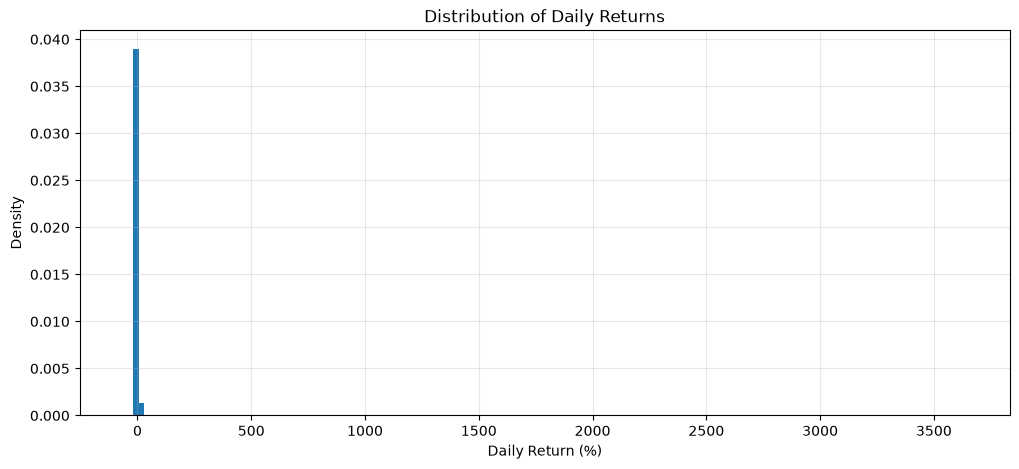

In [21]:
plt.figure(figsize=(12,5))

plt.hist(
    returns,
    bins=150,
    density=True
)

plt.title("Distribution of Daily Returns")
plt.xlabel("Daily Return (%)")
plt.ylabel("Density")

plt.grid(alpha=.3)

plt.show()

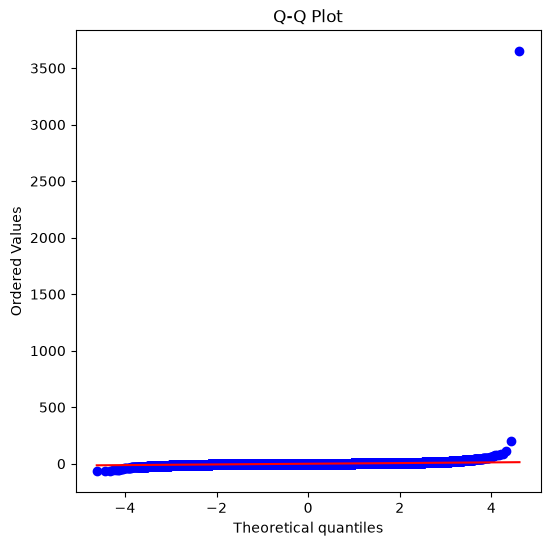

In [22]:
plt.figure(figsize=(6,6))

probplot(
    returns,
    dist="norm",
    plot=plt
)

plt.title("Q-Q Plot")

plt.show()

In [23]:
jb = jarque_bera(returns)

print("JB Statistic :", jb.statistic)
print("p-value      :", jb.pvalue)

if jb.pvalue < 0.05:
    print("Reject normality")
else:
    print("Cannot reject normality")

JB Statistic : 707005056997694.9
p-value      : 0.0
Reject normality


In [24]:
result = adfuller(returns)

print("ADF Statistic :", result[0])
print("p-value       :", result[1])

for k,v in result[4].items():
    print(k,v)

MemoryError: Unable to allocate 174. MiB for an array with shape (65, 351456) and data type float64